In [1]:
import torch
import torch.nn as nn
import torch.nn.functional as F

In [2]:
def softmax(x): return x.exp() / (x.exp().sum(-1)).unsqueeze(-1)
def nl(input, target): return -input[range(target.shape[0]), target].log().mean()


In [62]:
torch.manual_seed(3409)

xs = torch.randn(1, 32, 128, requires_grad=True)
ys = torch.randint(0, 32, (1, 200))
pred = softmax(xs)
loss=nl(pred, ys)
loss.backward()

In [63]:
loss

tensor(5.3500, grad_fn=<NegBackward0>)

In [64]:
xs.data.shape

torch.Size([1, 32, 128])

In [65]:
ys

tensor([[19, 11,  3, 29, 20, 30, 26, 11, 24, 20,  4, 25,  2, 27, 28,  2,  2, 30,
          1,  3,  5, 12, 16,  7, 16,  1, 11,  3, 21,  8, 16, 11, 23, 10, 27,  0,
         16,  1,  0, 27, 16,  7, 20, 14, 30,  5, 16, 25, 18,  5, 29, 19, 12, 19,
          1, 15, 30, 17, 13,  4, 18, 21, 26, 30, 12,  9, 28, 21, 14, 23, 10, 23,
         24, 26, 24,  6, 11,  3,  0, 19,  9, 22,  5, 22,  2,  6,  0, 30, 29,  8,
         29, 23,  3, 11, 23,  7, 19,  8,  2, 11, 25,  7,  4, 18, 22, 30, 28,  3,
          8, 11, 26, 21,  8, 25, 14, 26, 21,  8, 18, 12, 30, 18, 28, 15, 21, 12,
         31, 26, 26, 10,  0, 19,  5,  5, 23,  6, 23,  6,  1, 10, 27, 19, 28, 14,
          1, 28, 31, 20, 21,  8,  2,  7, 13, 14,  2, 26, 27, 27, 29, 25, 27, 13,
         31, 11,  3, 23, 23, 31, 24,  0,  0, 11,  6, 26,  9,  6, 31, 18, 10,  3,
         16, 25, 13, 10,  7, 29,  5, 12, 29, 13, 14, 14, 10, 18,  3,  5, 17,  2,
         17, 23]])

In [66]:
xs[0][0]

tensor([ 0.2477,  2.1216, -0.2116,  0.4789, -0.4160, -0.2979, -0.9301,  0.0093,
        -0.1425,  1.2056,  0.0730,  0.0337,  0.1864, -0.7447, -0.3213,  1.4942,
        -0.1217, -0.1753,  0.8064, -1.6774, -0.4290,  1.0829,  1.6881, -0.7816,
         1.8564,  0.7451,  1.5151,  1.8784, -1.9117, -1.9223, -0.4209, -0.2874,
         0.2812,  0.6796, -0.2272, -0.9019, -1.4081,  1.0384, -1.1369, -0.1989,
         0.7391, -0.0044, -1.0231, -0.9579,  0.5483,  0.2172, -1.2160,  0.7323,
         1.0075, -0.4825,  0.8612,  0.7025,  0.1696, -0.4791,  2.7641, -1.8844,
        -1.3353, -0.6209,  1.1714,  0.3407, -0.4861, -0.1093, -0.6350, -2.2045,
        -1.1086, -1.1483, -0.9295,  1.1658, -1.5843,  0.7970, -0.2946,  0.0586,
        -0.4055, -0.1317, -1.6202, -0.3920,  1.0112, -1.2633, -0.1917, -0.4220,
        -0.0631, -0.1078,  1.1869,  0.6931, -0.2247,  1.2639,  1.7215, -0.3158,
        -0.3923,  0.0120, -0.4947,  0.5219, -0.1930, -1.0496,  1.6341, -1.2221,
         0.6800, -0.9829, -0.5263,  0.99

In [6]:
import torch
import torch.nn as nn
import math


In [7]:
class Value:
    """ stores a single scalar value and its gradient """

    def __init__(self, data, _children=(), _op='', label=''):
        self.data = data
        self.grad = 0
        # internal variables used for autograd graph construction
        self._backward = lambda: None
        self._prev = set(_children)
        self._op = _op # the op that produced this node, for graphviz / debugging / etc
        self.label = label

    def __add__(self, other):
        other = other if isinstance(other, Value) else Value(other)
        out = Value(self.data + other.data, (self, other), '+')

        def _backward():
            self.grad += out.grad
            other.grad += out.grad
            print(" add backward ", self.grad, other.grad, out )
        out._backward = _backward

        return out

    def __mul__(self, other):
        other = other if isinstance(other, Value) else Value(other)
        out = Value(self.data * other.data, (self, other), '*')

        def _backward():
            self.grad += other.data * out.grad
            other.grad += self.data * out.grad
            print(" mul backward ", self.grad, other.grad, out )
        out._backward = _backward

        return out

    def exp(self):
        x = self.data
        out = Value(math.exp(x), (self, ), 'exp')
        
        def _backward():
          self.grad += out.data * out.grad # NOTE: in the video I incorrectly used = instead of +=. Fixed here.
          print(" exp backward ", self.grad, out )
        out._backward = _backward
        
        return out
    
    def __pow__(self, other):
        assert isinstance(other, (int, float)), "only supporting int/float powers for now"
        out = Value(self.data**other, (self,), f'**{other}')

        def _backward():
            self.grad += (other * self.data**(other-1)) * out.grad
            print(" pow backward ", self.grad, out, self.data, other, out.grad )
        out._backward = _backward

        return out

    def relu(self):
        out = Value(0 if self.data < 0 else self.data, (self,), 'ReLU')

        def _backward():
            self.grad += (out.data > 0) * out.grad
        out._backward = _backward

        return out

    # sigmoid activation function
    def sigmoid(self):
        x = self.data
        t = 1/(1+(math.exp(-x)))
        out = Value(t, (self, ), 'sigmoid')
        
        def _backward():
            f = 1/(1+(math.exp(-x)))
            self.grad += (f*(1 - f)) * out.grad
            print(" sigmoid backward ", f, self.grad, out )
        out._backward = _backward
        return out

    
    def log(self):
        # natural logarithm ln(x)
        if self.data <= 0:
            raise ValueError("log(x) requires x > 0")
    
        out = Value(math.log(self.data), (self,), 'log')
    
        def _backward():
            # d/dx log(x) = 1/x
            self.grad += (1.0 / self.data) * out.grad
            print(" log backward ", self.grad, out )
    
        out._backward = _backward
        return out
    
    def backward(self):

        # topological order all of the children in the graph
        topo = []
        visited = set()
        def build_topo(v):
            if v not in visited:
                print( "v ", v)
                visited.add(v)
                for child in v._prev:
                    print( "child ", child)
                    build_topo(child)
                topo.append(v)
        build_topo(self)

        # go one variable at a time and apply the chain rule to get its gradient
        self.grad = 1
        for v in reversed(topo):
            v._backward()

    def __neg__(self): # -self
        return self * -1

    def __radd__(self, other): # other + self
        return self + other

    def __sub__(self, other): # self - other
        return self + (-other)

    def __rsub__(self, other): # other - self
        return other + (-self)

    def __rmul__(self, other): # other * self
        return self * other

    def __truediv__(self, other): # self / other
        return self * other**-1

    def __rtruediv__(self, other): # other / self
        return other * self**-1

    def __repr__(self):
        return f"Value(data={self.data}, grad={self.grad})"

In [8]:
from graphviz import Digraph
def trace(root):
    nodes, edges = set(), set()
    def build(v):
        if v not in nodes:
            nodes.add(v)
            for child in v._prev:
                edges.add((child, v))
                build(child)
    build(root)
    return nodes, edges

def draw_dot(root, format='svg', rankdir='LR'):
    """
    format: png | svg | ...
    rankdir: TB (top to bottom graph) | LR (left to right)
    """
    assert rankdir in ['LR', 'TB']
    nodes, edges = trace(root)
    dot = Digraph(format=format, graph_attr={'rankdir': rankdir}) #, node_attr={'rankdir': 'TB'})
    
    for n in nodes:
        dot.node(name=str(id(n)), label = "{ %s | data %.4f | grad %.4f }" % (n.label, n.data, n.grad), shape='record')
        if n._op:
            dot.node(name=str(id(n)) + n._op, label=n._op)
            dot.edge(str(id(n)) + n._op, str(id(n)))
    
    for n1, n2 in edges:
        dot.edge(str(id(n1)), str(id(n2)) + n2._op)
    
    return dot

In [77]:
code = """
# -------------------------------------------------
# micrograd graph for d = a*b + c
# -------------------------------------------------
a = Value(2.0); a.label = "a"
b = Value(-3.0); b.label = "b"
c = Value(10.0); c.label = "c"

d = a * b + c
d.label = "d"

d.backward()
"""

In [78]:
exec(code)

v  Value(data=4.0, grad=0)
child  Value(data=10.0, grad=0)
v  Value(data=10.0, grad=0)
child  Value(data=-6.0, grad=0)
v  Value(data=-6.0, grad=0)
child  Value(data=-3.0, grad=0)
v  Value(data=-3.0, grad=0)
child  Value(data=2.0, grad=0)
v  Value(data=2.0, grad=0)
 add backward  1 1 Value(data=4.0, grad=1)
 mul backward  -3.0 2.0 Value(data=-6.0, grad=1)


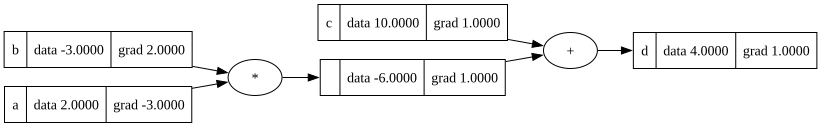

In [79]:
draw_dot(d)

In [146]:
code = """
# -------------------------------------------------
# micrograd graph for d = a*b + c
# -------------------------------------------------
a = Value(2.0); a.label = "a"
b = Value(-3.0); b.label = "b"
c = Value(10.0); c.label = "c"

d = a * b + c
d.label = "d"

d.backward()
"""

In [147]:
len(code)

274

In [148]:
code

'\n# -------------------------------------------------\n# micrograd graph for d = a*b + c\n# -------------------------------------------------\na = Value(2.0); a.label = "a"\nb = Value(-3.0); b.label = "b"\nc = Value(10.0); c.label = "c"\n\nd = a * b + c\nd.label = "d"\n\nd.backward()\n'

In [149]:
exec(code)

v  Value(data=4.0, grad=0)
child  Value(data=10.0, grad=0)
v  Value(data=10.0, grad=0)
child  Value(data=-6.0, grad=0)
v  Value(data=-6.0, grad=0)
child  Value(data=-3.0, grad=0)
v  Value(data=-3.0, grad=0)
child  Value(data=2.0, grad=0)
v  Value(data=2.0, grad=0)
 add backward  1 1 Value(data=4.0, grad=1)
 mul backward  -3.0 2.0 Value(data=-6.0, grad=1)


In [150]:
code += 'print(d)\n'

In [151]:
exec(code)

v  Value(data=4.0, grad=0)
child  Value(data=-6.0, grad=0)
v  Value(data=-6.0, grad=0)
child  Value(data=-3.0, grad=0)
v  Value(data=-3.0, grad=0)
child  Value(data=2.0, grad=0)
v  Value(data=2.0, grad=0)
child  Value(data=10.0, grad=0)
v  Value(data=10.0, grad=0)
 add backward  1 1 Value(data=4.0, grad=1)
 mul backward  -3.0 2.0 Value(data=-6.0, grad=1)
Value(data=4.0, grad=1)


In [73]:
code = """
"""

In [153]:
code += 'print(1)\n'

In [154]:
exec(code)

1


In [74]:
alfabet = 'abcdefghijkl'
index = 0
for k in range(3):
    code += 'a = Value(X); a.label = "a"\n'
    index += 1

In [75]:
code

'\na = Value(X); a.label = "a"\na = Value(X); a.label = "a"\na = Value(X); a.label = "a"\n'

In [12]:
exec(code)

In [13]:
code += 'd = a * a\n'

In [14]:
code += 'd.backward()\n'

In [40]:
# change variable for Values ( test )

In [76]:
index = 0
prev = ""
alfabet = "abcdefg"
A_INDEX = 0
fixed_string = ""

for s in code:
    if (prev == '\n' and s == 'a'):
        print(index, s)
        fixed_string += str(alfabet[A_INDEX])
        A_INDEX += 1
    else:
        fixed_string += s
    prev = s
    index += 1

1 a
29 a
57 a


In [77]:
fixed_string

'\na = Value(X); a.label = "a"\nb = Value(X); a.label = "a"\nc = Value(X); a.label = "a"\n'

In [36]:
fixed_string += 'd = a * a\n'

In [37]:
fixed_string += 'd.backward()\n'

In [38]:
exec(fixed_string)

TypeError: unsupported operand type(s) for *: 'set' and 'set'

In [39]:
# change {k} to number

In [78]:
index = 0
prev = ""
numbers = [2.0, -3.0, 6.0]
A_INDEX = 0
fixed_string1 = ""

for s in fixed_string:
    if (prev == '(' and s == 'X'):
        print(index, s)
        fixed_string1 += str(numbers[A_INDEX])
        A_INDEX += 1
    else:
        fixed_string1 += s    
    prev = s
    index += 1

11 X
39 X
67 X


In [79]:
fixed_string1

'\na = Value(2.0); a.label = "a"\nb = Value(-3.0); a.label = "a"\nc = Value(6.0); a.label = "a"\n'

In [80]:
fixed_string1 += 'd = a * b + c\n'
fixed_string1 += 'd.backward()\n'

In [81]:
exec(fixed_string1)

v  Value(data=0.0, grad=0)
child  Value(data=-6.0, grad=0)
v  Value(data=-6.0, grad=0)
child  Value(data=2.0, grad=0)
v  Value(data=2.0, grad=0)
child  Value(data=-3.0, grad=0)
v  Value(data=-3.0, grad=0)
child  Value(data=6.0, grad=0)
v  Value(data=6.0, grad=0)
 add backward  1 1 Value(data=0.0, grad=1)
 mul backward  -3.0 2.0 Value(data=-6.0, grad=1)


In [82]:
d

Value(data=0.0, grad=1)

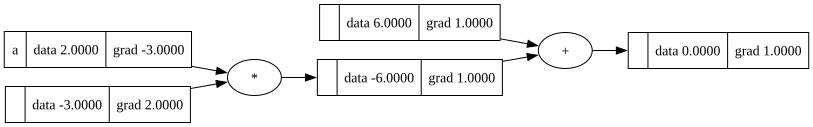

In [83]:
draw_dot(d)

In [84]:
import re

In [142]:
res = re.search(r"popular", s)

In [143]:
fmatch(".label", fixed_string1)

False

In [148]:
fixed_string1

'\na = Value(2.0); a.label = "a"\nb = Value(-3.0); a.label = "a"\nc = Value(6.0); a.label = "a"\nd = a * b + c\nd.backward()\n'

In [155]:
cnt = 0
pattern = r'.label'
test_string = fixed_string1
for match in re.finditer(pattern, test_string, re.IGNORECASE):
    cnt += 1
    print( cnt, " st match start index", match.start(), " end match index " , match.end())

1  st match start index 18  end match index  24
2  st match start index 49  end match index  55
3  st match start index 79  end match index  85


In [158]:
fixed_string1[24+3]

'"'

In [210]:
# USING CODE API functions 
# https://docs.pytorch.org/docs/2.14/generated/torch.nn.NLLLoss.html
# https://docs.pytorch.org/docs/2.14/generated/torch.nn.LogSoftmax.html

In [190]:
xs = torch.tensor([[ 0.2477,  2.1216, -0.2116,  0.4789, -0.4290,  1.0829,  1.6881, -0.7816, -0.0902,  0.2235]], requires_grad=True)

In [191]:
loss = torch.nn.LogSoftmax(dim=1)

In [192]:
loss(xs)

tensor([[-2.9171, -1.0432, -3.3764, -2.6859, -3.5938, -2.0819, -1.4767, -3.9464,
         -3.2550, -2.9413]], grad_fn=<LogSoftmaxBackward0>)

In [193]:
loss_fn = nn.NLLLoss()

In [196]:
final_loss = loss_fn(loss(xs), torch.tensor([9]))

In [197]:
final_loss.backward()

In [198]:
final_loss

tensor(2.9413, grad_fn=<NllLossBackward0>)

In [199]:
xs.grad

tensor([[ 0.0541,  0.3523,  0.0342,  0.0682,  0.0275,  0.1247,  0.2284,  0.0193,
          0.0386, -0.9472]])

In [200]:
# with 2 branches

In [219]:
xs = torch.tensor([[ 0.2477,  2.1216, -0.2116,  0.4789, -0.4290,  1.0829,  1.6881, -0.7816, -0.0902,  0.2235],  [-0.5434, -0.8391, -1.9117, -1.9223, -0.4209, -0.2874,  0.7715,  0.7912,0.2874, -0.4553]], requires_grad=True)

In [220]:
xs

tensor([[ 0.2477,  2.1216, -0.2116,  0.4789, -0.4290,  1.0829,  1.6881, -0.7816,
         -0.0902,  0.2235],
        [-0.5434, -0.8391, -1.9117, -1.9223, -0.4209, -0.2874,  0.7715,  0.7912,
          0.2874, -0.4553]], requires_grad=True)

In [221]:
loss(xs)

tensor([[-2.9171, -1.0432, -3.3764, -2.6859, -3.5938, -2.0819, -1.4767, -3.9464,
         -3.2550, -2.9413],
        [-2.7462, -3.0419, -4.1145, -4.1251, -2.6237, -2.4902, -1.4313, -1.4116,
         -1.9154, -2.6581]], grad_fn=<LogSoftmaxBackward0>)

In [222]:
final_loss = loss_fn(loss(xs), torch.tensor([9, 4]))

In [223]:
final_loss

tensor(2.7825, grad_fn=<NllLossBackward0>)

In [224]:
final_loss.backward()

In [225]:
xs.grad

tensor([[ 0.0270,  0.1762,  0.0171,  0.0341,  0.0137,  0.0623,  0.1142,  0.0097,
          0.0193, -0.4736],
        [ 0.0321,  0.0239,  0.0082,  0.0081, -0.4637,  0.0414,  0.1195,  0.1219,
          0.0736,  0.0350]])

In [228]:
# test - whether an exception is thrown if the index is out of bounds
# The vector has 10 parameters, which means there are 10 possible indices.
# try 10 index

In [229]:
final_loss = loss_fn(loss(xs), torch.tensor([10, 4]))

IndexError: Target 10 is out of bounds.

In [211]:
from torchviz import make_dot

def render_graph(loss, params, filename="graph", format="png"):
    """
    Renders the autograd graph using torchviz.

    Args:
        loss (torch.Tensor): Final scalar tensor (e.g., loss)
        params (dict): Named parameters to show in graph
        filename (str): Output file name (without extension)
        format (str): File format (png, pdf, etc.)
    """
    dot = make_dot(loss, params=params)
    dot.format = format
    dot.render(filename, cleanup=True)
    return dot

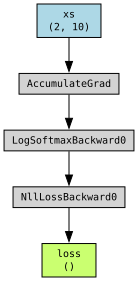

In [213]:
params = {
    "xs": xs,
    "loss": final_loss
}

render_graph(final_loss, params, filename="logistic_graph")